# QuantumBridge 量子蒙特卡洛与可微金融研究

真实股票历史回放 / Local execution, not hardware

<section class="qb-cloud-update"><strong>夸父新 SDK 更新 · quafu-sdk 0.2.7</strong><p>待提交：新 SDK 凭据未配置</p><a href="#quafu-sdk-update">查看本例新版云流程、数据与收据</a> · <a href="index.html#quafu-sdk-updates">本领域更新清单</a><p>不是网页实时求解。原结果保留。新 SDK 真机任务尚无结果时不会显示为已完成。</p></section>

## 真实数据与运行条件 / Real data & reproducibility

输入是 MSFT、IBM、SBUX、AAPL 的真实历史价格序列，不是生成的股票数据。
固定训练窗口为 **2015-01-02 至 2015-12-31（252 个交易日）**；组合验证使用 2016 年的独立留出窗口。
行情来源为 Plotly 公开数据仓库，数据字节以 SHA-256 验证，源提交和许可保存在包内。
原始复权方法未得到独立核验，因此价格、单股成本与损益均为**来源价格口径的历史回放**，不宣称经审计总收益或今天可以买卖的报价。

在本仓库安装 `pip install -e ".[finance-apps]"`，另装 `jupyter nbconvert matplotlib`，选择同一个 Python 内核。
本 Notebook 可在仓库根目录从上到下运行；不自动联网、不读取 token、不提交云任务。
包内数据支持离线重跑，改变参数后得到的是重新计算的模型结果。

所有金额均为 USD。定价是模型估值而非已观测期权成交价；历史风险与未来风险不等价。
读取、统计、分箱和一般状态制备都有经典成本；这里不假设免费 QRAM，也未建立端到端量子加速。

In [1]:
import sys, json, importlib.metadata, html
import numpy as np
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from quantumbridge.finance import (
    load_stock_history, build_portfolio_cqm, solve_portfolio,
    pricing_case, risk_case, pennylane_qmc, hybrid_volatility_case,
)
from quantumbridge.finance.gate_exports import measurement_artifact
SHOTS, SEED = 1024, 20261102
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
versions = {p: importlib.metadata.version(p) for p in ['numpy','scipy','dimod','pennylane','torch']}
print('Python', sys.version.split()[0], '| installed dependencies:', versions)
print('Hardware jobs: 0 | Frozen historical replay, not current quotes or investment advice')

def table(rows):
    keys = list(rows[0])
    def cell(value):
        return html.escape(f'{value:.6g}' if isinstance(value, (float, np.floating)) else str(value))
    markup = '<div class="qb-table"><table><thead><tr>'+''.join('<th>'+cell(k)+'</th>' for k in keys)+'</tr></thead><tbody>'
    markup += ''.join('<tr>'+''.join('<td>'+cell(row[k])+'</td>' for k in keys)+'</tr>' for row in rows)
    display(HTML(markup+'</tbody></table></div>'))

def clean(value):
    if isinstance(value, dict):
        return {k: clean(v) for k,v in value.items() if k not in ('circuit','circuits','preparation')}
    if isinstance(value, (list,tuple)): return [clean(v) for v in value]
    if isinstance(value, np.generic): return value.item()
    return value

history = load_stock_history()
print(json.dumps(history.provenance, ensure_ascii=False, indent=2))
table([dict(symbol=s, first=history.dates[0], last=history.dates[-1], source_price_usd=float(history.prices[-1,i]))
       for i,s in enumerate(history.symbols)])

Python 3.12.6 | installed dependencies: {'numpy': '2.4.6', 'scipy': '1.18.1', 'dimod': '0.12.22', 'pennylane': '0.44.1', 'torch': '2.12.0'}
Hardware jobs: 0 | Frozen historical replay, not current quotes or investment advice
{
  "provider": "Plotly public datasets / stockdata.csv",
  "source_url": "https://github.com/plotly/datasets/blob/0f7c47868a3393316098a8bf97d548e1ee23d22a/stockdata.csv",
  "download_url": "https://raw.githubusercontent.com/plotly/datasets/0f7c47868a3393316098a8bf97d548e1ee23d22a/stockdata.csv",
  "source_commit": "0f7c47868a3393316098a8bf97d548e1ee23d22a",
  "sha256": "60bf505fec160ce05ba959382adee32ea6e53ce14fe22886db27c58fe1b0d26b",
  "retrieved_date_utc": "2026-11-01",
  "observations": [
    "2007-01-03",
    "2016-03-01"
  ],
  "symbols": [
    "MSFT",
    "IBM",
    "SBUX",
    "AAPL",
    "GSPC"
  ],
  "currency": "USD",
  "license_url": "https://github.com/plotly/datasets/blob/master/LICENSE",
  "license_file": "PLOTLY_LICENSE.txt",
  "license": "MIT as p

symbol,first,last,source_price_usd
MSFT,2015-01-02,2015-12-31,55.0845
IBM,2015-01-02,2015-12-31,136.228
SBUX,2015-01-02,2015-12-31,59.8345
AAPL,2015-01-02,2015-12-31,104.692


<a id="pricing"></a>
## 1. 量子蒙特卡洛：IBM 欧式期权模型定价

输入是 IBM 2015 年真实价格，S₀ 为来源中 2015-12-31 的价格，σ 由训练期对数收益标准差年化。
示例假设 r=3%、零股息、剩余 30/252 年、K=S₀；这些是明确的模型参数，不是市场期权合约报价。
风险中性 Q 下的 GBM 为 Sᵀ = S₀ exp[(r−σ²/2)T + σ√T z]。
将标准正态等概率分为 8 格，采用各格中点分位数，支付为折现后的 max(Sᵀ−K,0) 或 max(K−Sᵀ,0)。

先把支付仿射归一化到 [0,1]，RY/CX 制备 A|0〉 = Σ√pᵢ |i〉(√(1−fᵢ)|0〉+√fᵢ|1〉)。
末位 1 的概率即 μ=Σpᵢfᵢ。QuantumBridge 运行 A、QA、Q²A、Q⁴A，
对各电路实际计数拟合 sin²[(2k+1)θ] 的二项似然，再反归一化得到金融金额。
不是从经典期望值直接填入“量子结果”。每个电路 1024 shots，共 4096 shots；
Grover 调用总计 7168，A/A† 等价制备调用总计 18432（不等于物理门数）。

比较三个量：连续 Black–Scholes、8 格经典精确期望、本地有限 shots 的 MLAE。
前两者差是模型离散化误差；后两者差才是本次估计误差，不能混在一起。

{'spot': 136.22849, 'strike': 136.22849, 'volatility': 0.2128641404065658, 'rate': 0.03, 'maturity_days': 30, 'dates': ['2015-01-02', '2015-12-31'], 'probability_measure': 'Risk-neutral Q; GBM, zero dividend yield assumed'}


scenario,probability,terminal_price,discounted_call,discounted_put
0,0.125,121.819,0,14.3584
1,0.125,127.747,0,8.45131
2,0.125,131.54,0,4.67195
3,0.125,134.781,0,1.44193
4,0.125,137.932,1.69754,0
5,0.125,141.331,5.08453,0
6,0.125,145.527,9.26577,0
7,0.125,152.609,16.3225,0


payoff,black_scholes,discrete,native_mlae,unamplified,grid_error,estimation_error,likelihood_95_interval
call,4.23107,4.04629,4.05883,4.2719,-0.184781,0.0125362,"[4.007773786244297, 4.1099722643667125]"
put,3.74541,3.61545,3.60551,3.51948,-0.129963,-0.00993496,"[3.5601710708152816, 3.6509270696583482]"


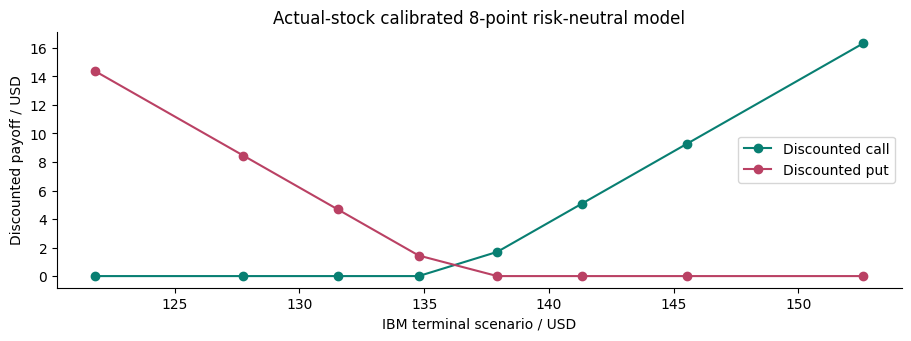

In [2]:
pricing = pricing_case(strike_ratio=1., rate=.03, maturity_days=30, shots=SHOTS, seed=SEED)
print({k:pricing[k] for k in ['spot','strike','volatility','rate','maturity_days','dates','probability_measure']})
table([dict(scenario=i, probability=p, terminal_price=s, discounted_call=c, discounted_put=v)
       for i,(p,s,c,v) in enumerate(zip(pricing['probabilities'],pricing['scenario_prices'],pricing['call_payoffs'],pricing['put_payoffs']))])
table([dict(payoff=k, black_scholes=pricing['black_scholes'][k], discrete=pricing[k]['exact_discrete'],
            native_mlae=pricing[k]['estimate'], unamplified=pricing[k]['unamplified_estimate'],
            grid_error=pricing[k]['exact_discrete']-pricing['black_scholes'][k],
            estimation_error=pricing[k]['estimate']-pricing[k]['exact_discrete'],
            likelihood_95_interval=pricing[k]['confidence_interval']) for k in ['call','put']])
fig, ax = plt.subplots(figsize=(9,3.3), layout='constrained')
ax.plot(pricing['scenario_prices'],pricing['call_payoffs'],'o-',label='Discounted call',color='#087f72')
ax.plot(pricing['scenario_prices'],pricing['put_payoffs'],'o-',label='Discounted put',color='#ba4164')
ax.set(xlabel='IBM terminal scenario / USD',ylabel='Discounted payoff / USD',title='Actual-stock calibrated 8-point risk-neutral model')
ax.legend(); plt.show()

## 2. 实际 PennyLane 参考调用和中间结果

下面真正调用已安装 PennyLane 的 `QuantumMonteCarlo` 模板和 `default.qubit`。
该模板用矩阵实现、不可直接求导，属于模拟器参考路径；不是夸父直接执行入口。
为避免平方反射的 μ 与 1−μ 相位歧义，支付编码到 [0,1/2]，取共轭峰折叠后的模态格点。
保留所有相位概率，5 个估计位加 4 个目标位共 9 比特，显示有限相位分辨率误差。
这与只需 4 比特的 Native MLAE 是两条不同实现路径，不把参考模板冒充原生完整替代。

{'backend': 'PennyLane.default.qubit / QuantumMonteCarlo', 'version': '0.44.1', 'estimate': 3.7050330586557436, 'phase': 0.21875, 'qubits': 9, 'estimation_wires': 5, 'exact_discrete': 4.046290235543493, 'hardware_jobs': 0, 'grid_amplitude': 0.1134947733186315, 'normalization': {'offset': 0.0, 'scale': 32.64496637439002, 'range': '[0, 1/2] to avoid reflection phase alias'}}


power,counts,successes,success_rate
0,"{'0': 756, '1': 268}",268,0.261719
1,{'1': 1024},1024,1
2,"{'1': 278, '0': 746}",278,0.271484
4,{'1': 1024},1024,1


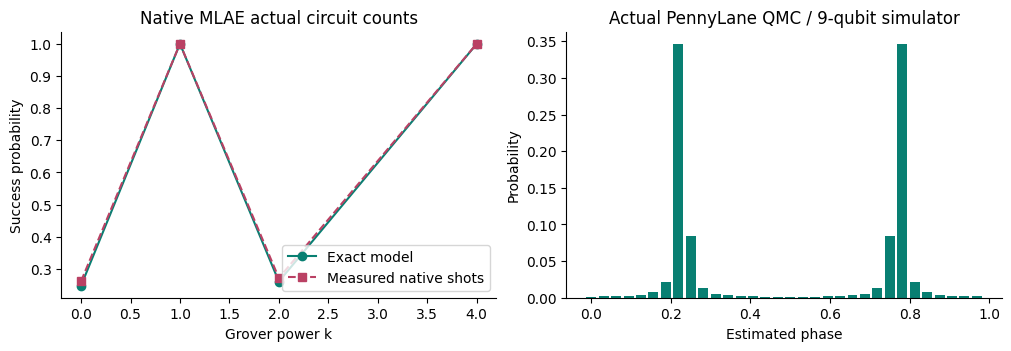

power,qubits,gates,two_qubit_gates,sha256
0,4,35,24,31b3bc5dd41fe450fe6f53683c3210452ad0b9b1d3cf043e3772041b768383dc
1,4,155,106,d8859ca7252a3b4dcd865dced86cfaa13d0bf67cbac2242237c1b2eb4ddaa54c
2,4,275,188,66261114513b1eb82d1ccb1e5b0b20e17e45acb63f46e38a2d30c2edbee591c5
4,4,515,352,87e5d4ee40c29b031f73f8f8312e0db10f2fb4749c73c787ed6b4d054a7d0e46


Native A / preparation circuit QASM2:
OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];
creg c[4];
ry(1.5707963267948966) q[0];
ry(1.5707963267948966) q[1];
ry(1.5707963267948966) q[2];
ry(0.83613924177580945) q[3];
cx q[2],q[3];
ry(-0.24532159515415741) q[3];
cx q[2],q[3];
cx q[1],q[3];
ry(-0.37589671088358145) q[3];
cx q[1],q[3];
cx q[1],q[3];
cx q[2],q[3];
ry(0.11343877898134817) q[3];
cx q[2],q[3];
cx q[1],q[3];
cx q[0],q[3];
ry(-0.83613924177580945) q[3];
cx q[0],q[3];
cx q[0],q[3];
cx q[2],q[3];
ry(0.24532159515415741) q[3];
cx q[2],q[3];
cx q[0],q[3];
cx q[0],q[3];
cx q[1],q[3];
ry(0.37589671088358145) q[3];
cx q[1],q[3];
cx q[0],q[3];
cx q[0],q[3];
cx q[1],q[3];
cx q[2],q[3];
ry(-0.11343877898134817) q[3];
cx q[2],q[3];
cx q[1],q[3];
cx q[0],q[3];
measure q[0] -> c[0];
measure q[1] -> c[1];
measure q[2] -> c[2];
measure q[3] -> c[3];



In [3]:
pl_reference = pennylane_qmc(pricing['probabilities'], pricing['call_payoffs'], estimation_wires=5)
print({k:v for k,v in pl_reference.items() if k != 'probabilities'})
q = pricing['call']
table([dict(power=k, counts=c, successes=n, success_rate=n/SHOTS)
       for k,c,n in zip(q['schedule'],q['counts'],q['good_counts'])])
fig, axes = plt.subplots(1,2,figsize=(10,3.4),layout='constrained')
theta = np.arcsin(np.sqrt((q['exact_discrete']-q['normalization']['offset'])/q['normalization']['scale']))
powers = np.array(q['schedule'])
axes[0].plot(powers,np.sin((2*powers+1)*theta)**2,'o-',label='Exact model',color='#087f72')
axes[0].plot(powers,np.array(q['good_counts'])/SHOTS,'s--',label='Measured native shots',color='#ba4164')
axes[0].set(xlabel='Grover power k',ylabel='Success probability',title='Native MLAE actual circuit counts'); axes[0].legend()
axes[1].bar(np.arange(32)/32,pl_reference['probabilities'],width=.025,color='#087f72')
axes[1].set(xlabel='Estimated phase',ylabel='Probability',title='Actual PennyLane QMC / 9-qubit simulator')
plt.show()
gate_artifacts = [measurement_artifact(c) for c in q['circuits']]
table([dict(power=k,qubits=a['num_qubits'],gates=a['gates'],two_qubit_gates=a['two_qubit_gates'],sha256=a['sha256'])
       for k,a in zip(q['schedule'],gate_artifacts)])
print('Native A / preparation circuit QASM2:'); print(gate_artifacts[0]['openqasm'])

<a id="risk"></a>
## 3. 风险计量：真实损失、VaR 与 CVaR

本金 1000 美元，真实日损失 Lₜ = −1000 rₜ，可为负值（盈利）。此处概率测度为历史 P，**不是定价的风险中性 Q**。
先从全部 251 个历史收益计算 95% VaR，以及含阈值处分数概率质量的 ES/CVaR。
按损失排序分为 8 组，以各组均值压缩，保留精确期望损失；分组会改变分位数和质心 CVaR，因此单独列出偏差。
为估计原历史分布的 CVaR，经典求得阈值 v，再对每组的 max(L−v,0) 求条件均值，
量子估计其期望；最后 CVaR = v + E[(L−v)⁺]/0.05。
这样尾部期望在离散化前后严格相同。**VaR 阈值仍是经典计算，不是量子分位数搜索。**
同一组尾部支付另交给真正的 PennyLane `QuantumMonteCarlo` 模板执行，
保留相位格点和全部概率。其有限相位分辨率误差会被 1/0.05 放大，不能用 MLAE 的采样区间替它背书。
95% 似然比区间仅是渐近采样区间包络，不包含模型、历史抽样不确定性或硬件误差，也不保证有限样本覆盖率。

bin,probability,mean_loss,mean_tail_excess
0,0.12749,-20.0855,0
1,0.12749,-10.4787,0
2,0.12749,-5.22813,0
3,0.123506,-1.64277,0
4,0.123506,1.88307,0
5,0.123506,6.015,0
6,0.123506,11.0524,0
7,0.123506,23.1522,4.71056


Full-history classical reference: {'confidence': 0.95, 'expected_loss': 0.43388088283397735, 'VaR': 20.98379725778987, 'CVaR_expected_shortfall': 32.61943323896854}
Centroid-only reference: {'confidence': 0.95, 'expected_loss': 0.43388088283397686, 'VaR': 23.152179577860856, 'CVaR_expected_shortfall': 23.152179577860856}


metric,historical,native_mlae,interval
Expected loss,0.433881,0.398211,"[0.27579858849664873, 0.5214754857873203]"
CVaR / ES,32.6194,32.4884,"[32.32242761777647, 32.6705699348764]"


Actual PennyLane tail-excess phase grid: {'backend': 'PennyLane.default.qubit / QuantumMonteCarlo', 'version': '0.44.1', 'estimate': 0.556216479798793, 'phase': 0.15625, 'qubits': 9, 'estimation_wires': 5, 'exact_discrete': 0.5817817990589338, 'hardware_jobs': 0, 'grid_amplitude': 0.059039367825822475, 'normalization': {'offset': 0.0, 'scale': 9.421111713793056, 'range': '[0, 1/2] to avoid reflection phase alias'}, 'cvar_estimate': 32.10812685376572, 'cvar_discrete_reference': 32.61943323896854}


metric,historical,native_mlae,pennylane_qmc,pennylane_grid_error
CVaR / ES,32.6194,32.4884,32.1081,-0.511306


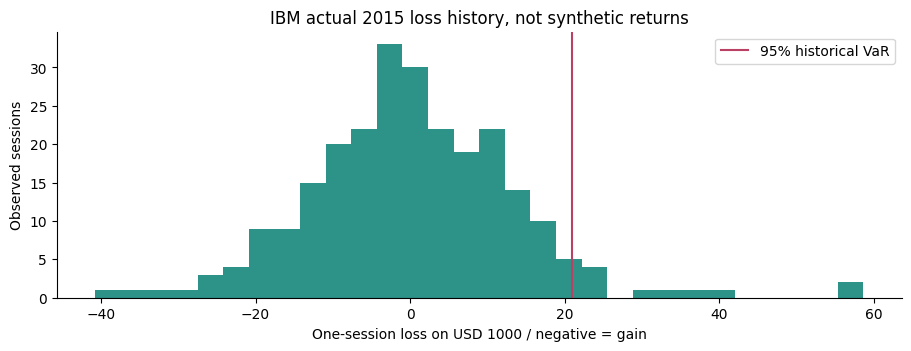

In [4]:
risk = risk_case(confidence=.95,notional=1000.,shots=SHOTS,seed=SEED)
table([dict(bin=i,probability=p,mean_loss=v,mean_tail_excess=e)
       for i,(p,v,e) in enumerate(zip(risk['probabilities'],risk['bin_values'],risk['excess_values']))])
print('Full-history classical reference:', {k:v for k,v in risk['raw_reference'].items() if k not in ['cdf','sorted_losses']})
print('Centroid-only reference:', {k:v for k,v in risk['centroid_binned_reference'].items() if k not in ['cdf','sorted_losses']})
table([dict(metric='Expected loss',historical=risk['raw_reference']['expected_loss'],native_mlae=risk['mean']['estimate'],interval=risk['mean']['confidence_interval']),
       dict(metric='CVaR / ES',historical=risk['raw_reference']['CVaR_expected_shortfall'],native_mlae=risk['cvar_estimate'],interval=risk['cvar_interval'])])
pl_risk_reference = pennylane_qmc(risk['probabilities'], risk['excess_values'], estimation_wires=5)
pl_risk_reference['cvar_estimate'] = risk['raw_reference']['VaR'] + pl_risk_reference['estimate']/(1-risk['confidence'])
pl_risk_reference['cvar_discrete_reference'] = risk['raw_reference']['VaR'] + pl_risk_reference['exact_discrete']/(1-risk['confidence'])
print('Actual PennyLane tail-excess phase grid:', {k:v for k,v in pl_risk_reference.items() if k != 'probabilities'})
table([dict(metric='CVaR / ES',historical=risk['raw_reference']['CVaR_expected_shortfall'],
            native_mlae=risk['cvar_estimate'],pennylane_qmc=pl_risk_reference['cvar_estimate'],
            pennylane_grid_error=pl_risk_reference['cvar_estimate']-pl_risk_reference['cvar_discrete_reference'])])
assert np.isclose(np.dot(risk['probabilities'],risk['bin_values']),np.mean(risk['losses']))
assert np.isclose(risk['raw_reference']['VaR']+np.dot(risk['probabilities'],risk['excess_values'])/.05,risk['raw_reference']['CVaR_expected_shortfall'])
assert np.isclose(pl_risk_reference['cvar_discrete_reference'],risk['raw_reference']['CVaR_expected_shortfall'])
fig, ax = plt.subplots(figsize=(9,3.4), layout='constrained')
ax.hist(risk['losses'],bins=30,color='#087f72',alpha=.85)
ax.axvline(risk['raw_reference']['VaR'],color='#ba4164',label='95% historical VaR')
ax.set(xlabel='One-session loss on USD 1000 / negative = gain',ylabel='Observed sessions',title='IBM actual 2015 loss history, not synthetic returns')
ax.legend(); plt.show()

<a id="hybrid"></a>
## 4. 可微分电路：混合波动模型研究

QMC 相位估计模板本身不可微；以下是**独立**的可训练模型，不能混为同一个可微算法。
用前两个已知日收益预测下一交易日绝对收益。最早 75% 为训练，末尾 25% 为验证，归一化仅从训练期估计。
2 比特 Native QNode 用 RY 编码、4 个旋转参数和 CNOT，测量 Z 期望；
经典线性头加 softplus 输出非负预测，PyTorch Adam 对量子参数和经典参数真实反向传播。
当前核心不支持本例多来源广播 backprop，因此逐条执行标量 QNode，**没有放宽资源上限**。
展示每轮损失、量子梯度范数、留出 MSE 与训练均值常数预测的 MSE。
若未优于常数基线也原样保留，不称为预测优势。

Training / validation dates: ['2015-01-07', '2015-10-01'] ['2015-10-02', '2015-12-31']


epoch,train_mse,quantum_gradient_norm
1,7.2909e-05,0.00640612
2,7.28068e-05,0.00352456
3,7.25956e-05,0.00139496
4,7.24284e-05,0.000830713
5,7.23227e-05,0.0032793
6,7.22654e-05,0.00594851
7,7.22187e-05,0.00869023
8,7.21541e-05,0.0113107
9,7.20716e-05,0.0136899
10,7.19846e-05,0.0157893


Real trained circuit parameters: [0.5436891472654173, -0.1902887424394269, -0.02339266552538731, -0.3258997203796482] | classical head: [-0.369248562806502, 0.6843136426398096]


validation_mse,constant_baseline_mse,beats_constant
9.70737e-05,9.45401e-05,False


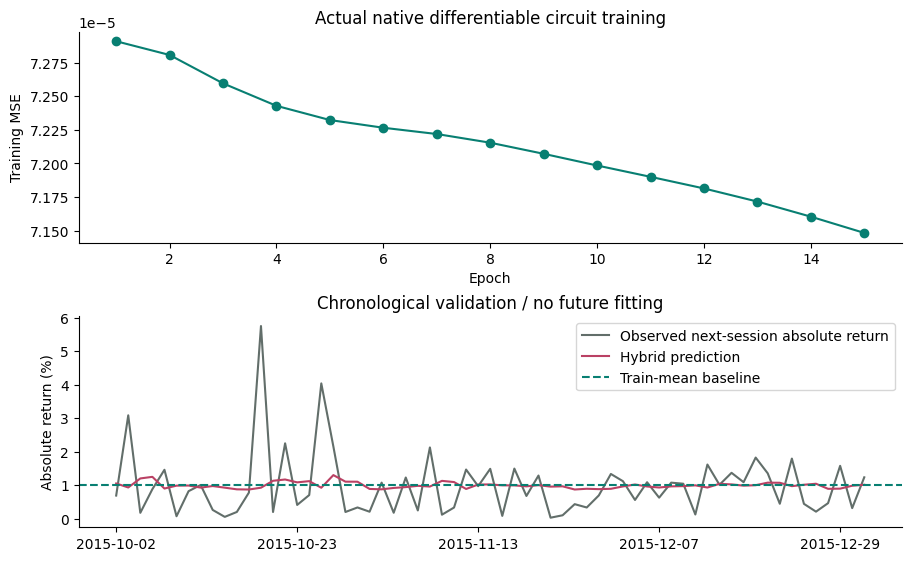

In [5]:
hybrid = hybrid_volatility_case(epochs=15,seed=SEED)
print('Training / validation dates:',hybrid['train_dates'],hybrid['validation_dates'])
table([dict(epoch=i+1,train_mse=mse,quantum_gradient_norm=g)
       for i,(mse,g) in enumerate(zip(hybrid['train_mse'],hybrid['circuit_gradient_norms']))])
print('Real trained circuit parameters:',hybrid['weights'],'| classical head:',hybrid['classical_head'])
table([dict(validation_mse=hybrid['validation_mse'],constant_baseline_mse=hybrid['baseline_mse'],
            beats_constant=hybrid['validation_mse'] < hybrid['baseline_mse'])])
fig, axes=plt.subplots(2,1,figsize=(9,5.5),layout='constrained')
axes[0].plot(range(1,16),hybrid['train_mse'],'o-',color='#087f72')
axes[0].set(xlabel='Epoch',ylabel='Training MSE',title='Actual native differentiable circuit training')
axes[1].plot(hybrid['dates'],np.array(hybrid['actual'])*100,label='Observed next-session absolute return',color='#626e6a')
axes[1].plot(hybrid['dates'],np.array(hybrid['predictions'])*100,label='Hybrid prediction',color='#ba4164')
axes[1].axhline(hybrid['target_scale']*100,color='#087f72',linestyle='--',label='Train-mean baseline')
axes[1].set(xticks=np.arange(0,len(hybrid['dates']),15),ylabel='Absolute return (%)',title='Chronological validation / no future fitting')
axes[1].legend(); plt.show()
qmc_evidence = dict(application='Native MLAE + PennyLane QMC + differentiable hybrid research',
                    pricing=clean(pricing), risk=clean(risk), hybrid=hybrid,
                    pennylane_reference=pl_reference, pennylane_risk_reference=pl_risk_reference,
                    gate_artifacts=gate_artifacts,
                    versions=versions, hardware_jobs=0)

## 运行边界与夸父迁移 / Limits & Quafu path

本次 **0 个云端/真机任务**，不消耗原金融批次额度、不改写其回执。
现有 D3 审计仍是 NO_NEW_SUBMISSION_RECOMMENDED；物理布局、位序和精度验收没有被本批模拟解除。
Native QAOA/MLAE 电路已分解为基础门并导出可检查的 QASM2，量子比特不超过 4；
QASM2 不能保存全局相位，因此导出显式记录所移除的顶层相位，只承诺终端测量概率，不能作为保相位受控子程序复用。
PennyLane 矩阵参考电路是 9 比特模拟，未承诺可在旧的 6 比特真机额度下运行。
未来接真机前需要独立核验 gate basis、耦合图、深度、布局、位序和额外任务预算；
深 Grover 电路可能受噪声限制，不能把成功序列化称为硬件可用，更不能声称量子优势。

本次只有小规模金融研究应用，并不表示已完成 Qiskit + PennyLane 全部核心函数融合或生产金融系统。

### 练习与解答骨架
改变预算或执行价，只使用训练期重新计算；比较目标、可行性、离散化和有限 shots 误差。
不要用留出期选择预算、股票、角度或训练超参数。

### 一手来源
- [D-Wave ExactCQMSolver：经典本地枚举](https://docs.dwavequantum.com/en/latest/ocean/api_ref_dimod/sampler_composites.html)
- [D-Wave 官方组合优化示例：概念参考，未复制源码](https://github.com/dwave-examples/portfolio-optimization)
- [PennyLane QuantumMonteCarlo：模板和模拟器限制](https://docs.pennylane.ai/en/stable/code/api/pennylane.QuantumMonteCarlo.html)
- [真实行情源：固定提交](https://github.com/plotly/datasets/blob/0f7c47868a3393316098a8bf97d548e1ee23d22a/stockdata.csv)
- [行情源仓库 MIT 许可](https://github.com/plotly/datasets/blob/master/LICENSE)
- [原有夸父 D3 契约审计](finance_quafu_d3_client_contract.html)

QuantumBridge · 所属 相干(北京)科技有限公司

In [6]:
print('EVIDENCE_JSON='+json.dumps(qmc_evidence, ensure_ascii=False, allow_nan=False))

EVIDENCE_JSON={"application": "Native MLAE + PennyLane QMC + differentiable hybrid research", "pricing": {"source": {"provider": "Plotly public datasets / stockdata.csv", "source_url": "https://github.com/plotly/datasets/blob/0f7c47868a3393316098a8bf97d548e1ee23d22a/stockdata.csv", "download_url": "https://raw.githubusercontent.com/plotly/datasets/0f7c47868a3393316098a8bf97d548e1ee23d22a/stockdata.csv", "source_commit": "0f7c47868a3393316098a8bf97d548e1ee23d22a", "sha256": "60bf505fec160ce05ba959382adee32ea6e53ce14fe22886db27c58fe1b0d26b", "retrieved_date_utc": "2026-11-01", "observations": ["2007-01-03", "2016-03-01"], "symbols": ["MSFT", "IBM", "SBUX", "AAPL", "GSPC"], "currency": "USD", "license_url": "https://github.com/plotly/datasets/blob/master/LICENSE", "license_file": "PLOTLY_LICENSE.txt", "license": "MIT as published by the source repository; original upstream data methodology is not documented", "price_basis": "Source-published historical price series. Split/dividend adjustm

<a id="quafu-sdk-update"></a>
## 夸父 SDK 更新 / Quafu SDK update · 2026-11-16

**状态：待提交：新 SDK 凭据未配置**。原案例、模型输入、实验输出和历史真机收据完整保留在前文；以下是独立的新版本验证，不替换原结果。原始状态码保存在 JSON 收据中。

本地复验的原始时间：**2026-11-16T07:11:01.697257+00:00**。后续云收据刷新只更新云证据，不把冻结的本地结果改写成刚刚重新执行。

[本领域更新清单](index.html#quafu-sdk-updates) · [本例 JSON 收据与计划](../../downloads/quafu-cases-20261116/finance--qmc_hybrid.json) · [计数 CSV](../../downloads/quafu-cases-20261116/finance--qmc_hybrid.csv) · [图形 PNG](../../downloads/quafu-cases-20261116/finance--qmc_hybrid.png) · [全量可复现包](../../downloads/quafu-cases-20261116/reproduction.zip)

### 原理与执行步骤

1. 保留本例的经典输入、优化、模型与安全边界；仅把已绑定的门线路导出为 OpenQASM 2.0。D-Wave CQM 不会直接送到门型芯片；PQC/AES 也不是量子任务。
2. 使用 **quafu-sdk 0.2.7** 独立环境。它与旧 `pyquafu` 使用相同的 `quafu` 导入名，不应装入同一环境。官方版本与来源检查时间见后端快照。
3. 查询 `devices()` 与 `Client.metadata("Baihua")["limits"]`。本次公开快照时间 **2026-11-16T06:37:26.459015+00:00**；只通过逻辑比特/shots/哈希预检，不代表物理布线编译成功。后端变化必须重新查询，不把本表写死为永久约束。
4. `submit(..., target="Baihua", compiler="qiskit", shots=1024)` 请求平台编译。`compiler="none"` 仅限已经过物理门集与耦合验证的线路，本例不使用。保留编译器版本、seed、执行线路、虚拟/物理测量映射和校准 ID；平台没返回的字段不猜测。
5. 提交后立即保存 **任务组 job.id**，随后用 `client.job(job_id)` 恢复查询；最终 **result.task_id** 是组内任务号，两者不能混用。超时只结束等待，不取消也不重提任务；未知提交状态留下 durable intent 待人工对账。
6. 原始结果位序为 **c0_rightmost**，本项目图表显示 **q0-first**。本例完整测量 q[i]→c[i]，同时核实 provider `measurements`，因此标签反转；不按噪声分布“猜位序”。Cirq 的原 ancilla/位置边缘分布与新全寄存器测量分开保留。
7. 对账 `sum(counts)==shots_returned`；按实际返回次数归一化，而不是默认除以请求值。保留请求/返回差额。冻结源线路哈希、输入来源、SDK 身份、后端约束与执行收据；真机噪声不能用本地随机种子精确复现。

当前没有新 SDK 云结果时，task_id、编译后线路、实际 shots 和云结果保持空值，**不把本地采样或旧 Dongling 收据冒充新版百花结果**。非真实硬件熵源的 QRNG 不能认证为安全随机数，BB84 电路演示也不是真实通信链路。


<div class="qb-cloud-table"><table><thead><tr><th>实验</th><th>比特</th><th>逻辑门/深度</th><th>编译</th><th>请求/返回 shots</th><th>job_id / task_id</th><th>状态</th></tr></thead><tbody><tr><td>inference-2015-10-02</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-05</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-06</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-07</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-08</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-09</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-12</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-13</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-14</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-15</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-16</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-19</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-20</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-21</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-22</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-23</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-26</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-27</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-28</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-29</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-10-30</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-02</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-03</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-04</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-05</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-06</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-09</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-10</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-11</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-12</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-13</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-16</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-17</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-18</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-19</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-20</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-23</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-24</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-25</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-27</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-11-30</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-01</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-02</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-03</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-04</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-07</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-08</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-09</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-10</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-11</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-14</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-15</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-16</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-17</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-18</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-21</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-22</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-23</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-24</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-28</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-29</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-30</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr><tr><td>inference-2015-12-31</td><td>2</td><td>7/6</td><td>provider qiskit / pending</td><td>1024/—</td><td>— / —</td><td>NOT_SUBMITTED_NEW_SDK_CREDENTIALS_REQUIRED</td></tr></tbody></table></div>

<h3>后端当前约束 / Public backend limits</h3><div class="qb-cloud-table"><table><thead><tr><th>字段</th><th>值</th></tr></thead><tbody><tr><td>max_qubits</td><td>156</td></tr><tr><td>qubit_count</td><td>declared</td></tr><tr><td>guest_max_qubits</td><td>None</td></tr><tr><td>min_shots</td><td>1024</td></tr><tr><td>max_shots</td><td>8192</td></tr><tr><td>shots_step</td><td>1024</td></tr><tr><td>guest_max_shots</td><td>1024</td></tr><tr><td>max_depth</td><td>None</td></tr><tr><td>wall_s</td><td>None</td></tr><tr><td>max_memory_mb</td><td>None</td></tr><tr><td>max_tasks_per_job</td><td>500</td></tr><tr><td>method</td><td>hardware</td></tr></tbody></table></div><div class="qb-cloud-table"><table><thead><tr><th>字段</th><th>值</th></tr></thead><tbody><tr><td>native basis</td><td>h, rx, ry, rz, cz</td></tr><tr><td>coupling edges</td><td>114</td></tr><tr><td>directed coupling</td><td>False</td></tr><tr><td>calibration ID</td><td>b43d6a378c70ed9f</td></tr><tr><td>physical layout audit</td><td>等待真实 executed_qasm 与 measurements；不可从逻辑比特推断</td></tr></tbody></table></div>

### 可运行的新 SDK 代码

默认不联网、不读凭据、不提交。解压上方可复现包，在干净的 `quafu-sdk==0.2.7` 环境中运行；新凭据由 SDK 从 `QUAFU_API_KEY` 或其已保存登录态读取，不在 Notebook 中填写或输出密钥。明确设置 `RUN_CLOUD=True` 且填写已批准的任务上限才会执行。

In [1]:
import json
from pathlib import Path
RUN_CLOUD = False
APPROVED_MAX_TASKS = 0
if RUN_CLOUD and True:
    import quafu
    from quafu_case_runtime import run_manifest
    # Run beside the extracted reproduction bundle. The default branch below
    # does not read local credentials or require any downloaded files.
    data = json.loads(Path("finance--qmc_hybrid.json").read_text())
    frozen = json.loads(Path("execution-plan.json").read_text())
    ids = [e["kernel_id"] for e in data["case"]["experiments"]]
    case_plan = {"kernels": {key: frozen["kernels"][key] for key in ids}}
    client = quafu.Client()  # existing SDK identity; never write a key here
    journal = run_manifest(client, case_plan, Path("finance--qmc_hybrid-private-journal.json"),
                           max_tasks=APPROVED_MAX_TASKS, execute=True, timeout=30)
    for entry in journal["jobs"].values():
        print(entry.get("job_id"), entry.get("state"))
else:
    print("Cloud submission disabled; historical and fresh local outputs are separate.")


Cloud submission disabled; historical and fresh local outputs are separate.


<h3>独立本地复验 / Fresh local replay (not cloud)</h3><div class="qb-cloud-table"><table><thead><tr><th>实验</th><th>q0-first</th><th>预期 provider c0-rightmost</th><th>本地 counts</th><th>本地 P</th><th>理想 P</th><th>新云 counts</th></tr></thead><tbody><tr><td>inference-2015-10-02</td><td>00</td><td>00</td><td>529</td><td>0.516602</td><td>0.499332</td><td>—</td></tr><tr><td>inference-2015-10-02</td><td>01</td><td>10</td><td>330</td><td>0.322266</td><td>0.324635</td><td>—</td></tr><tr><td>inference-2015-10-02</td><td>10</td><td>01</td><td>64</td><td>0.0625</td><td>0.073176</td><td>—</td></tr><tr><td>inference-2015-10-02</td><td>11</td><td>11</td><td>101</td><td>0.098633</td><td>0.102856</td><td>—</td></tr><tr><td>inference-2015-10-05</td><td>00</td><td>00</td><td>861</td><td>0.84082</td><td>0.826539</td><td>—</td></tr><tr><td>inference-2015-10-05</td><td>01</td><td>10</td><td>132</td><td>0.128906</td><td>0.135145</td><td>—</td></tr><tr><td>inference-2015-10-05</td><td>10</td><td>01</td><td>6</td><td>0.005859</td><td>0.004847</td><td>—</td></tr><tr><td>inference-2015-10-05</td><td>11</td><td>11</td><td>25</td><td>0.024414</td><td>0.033469</td><td>—</td></tr><tr><td>inference-2015-10-06</td><td>00</td><td>00</td><td>209</td><td>0.204102</td><td>0.188724</td><td>—</td></tr><tr><td>inference-2015-10-06</td><td>01</td><td>10</td><td>27</td><td>0.026367</td><td>0.019325</td><td>—</td></tr><tr><td>inference-2015-10-06</td><td>10</td><td>01</td><td>88</td><td>0.085938</td><td>0.082882</td><td>—</td></tr><tr><td>inference-2015-10-06</td><td>11</td><td>11</td><td>700</td><td>0.683594</td><td>0.709069</td><td>—</td></tr><tr><td>inference-2015-10-07</td><td>00</td><td>00</td><td>180</td><td>0.175781</td><td>0.162173</td><td>—</td></tr><tr><td>inference-2015-10-07</td><td>01</td><td>10</td><td>829</td><td>0.80957</td><td>0.817063</td><td>—</td></tr><tr><td>inference-2015-10-07</td><td>10</td><td>01</td><td>13</td><td>0.012695</td><td>0.017644</td><td>—</td></tr><tr><td>inference-2015-10-07</td><td>11</td><td>11</td><td>2</td><td>0.001953</td><td>0.003121</td><td>—</td></tr><tr><td>inference-2015-10-08</td><td>00</td><td>00</td><td>932</td><td>0.910156</td><td>0.902473</td><td>—</td></tr><tr><td>inference-2015-10-08</td><td>01</td><td>10</td><td>29</td><td>0.02832</td><td>0.0276</td><td>—</td></tr><tr><td>inference-2015-10-08</td><td>10</td><td>01</td><td>1</td><td>0.000977</td><td>0.001927</td><td>—</td></tr><tr><td>inference-2015-10-08</td><td>11</td><td>11</td><td>62</td><td>0.060547</td><td>0.068001</td><td>—</td></tr><tr><td>inference-2015-10-09</td><td>00</td><td>00</td><td>705</td><td>0.688477</td><td>0.679608</td><td>—</td></tr><tr><td>inference-2015-10-09</td><td>01</td><td>10</td><td>114</td><td>0.111328</td><td>0.103477</td><td>—</td></tr><tr><td>inference-2015-10-09</td><td>10</td><td>01</td><td>33</td><td>0.032227</td><td>0.031778</td><td>—</td></tr><tr><td>inference-2015-10-09</td><td>11</td><td>11</td><td>172</td><td>0.167969</td><td>0.185137</td><td>—</td></tr><tr><td>inference-2015-10-12</td><td>00</td><td>00</td><td>724</td><td>0.707031</td><td>0.703092</td><td>—</td></tr><tr><td>inference-2015-10-12</td><td>01</td><td>10</td><td>296</td><td>0.289062</td><td>0.292689</td><td>—</td></tr><tr><td>inference-2015-10-12</td><td>10</td><td>01</td><td>2</td><td>0.001953</td><td>0.001325</td><td>—</td></tr><tr><td>inference-2015-10-12</td><td>11</td><td>11</td><td>2</td><td>0.001953</td><td>0.002894</td><td>—</td></tr><tr><td>inference-2015-10-13</td><td>00</td><td>00</td><td>867</td><td>0.84668</td><td>0.836406</td><td>—</td></tr><tr><td>inference-2015-10-13</td><td>01</td><td>10</td><td>20</td><td>0.019531</td><td>0.023578</td><td>—</td></tr><tr><td>inference-2015-10-13</td><td>10</td><td>01</td><td>5</td><td>0.004883</td><td>0.004122</td><td>—</td></tr><tr><td>inference-2015-10-13</td><td>11</td><td>11</td><td>132</td><td>0.128906</td><td>0.135894</td><td>—</td></tr><tr><td>inference-2015-10-14</td><td>00</td><td>00</td><td>743</td><td>0.725586</td><td>0.718144</td><td>—</td></tr><tr><td>inference-2015-10-14</td><td>01</td><td>10</td><td>100</td><td>0.097656</td><td>0.090167</td><td>—</td></tr><tr><td>inference-2015-10-14</td><td>10</td><td>01</td><td>19</td><td>0.018555</td><td>0.019034</td><td>—</td></tr><tr><td>inference-2015-10-14</td><td>11</td><td>11</td><td>162</td><td>0.158203</td><td>0.172655</td><td>—</td></tr><tr><td>inference-2015-10-15</td><td>00</td><td>00</td><td>874</td><td>0.853516</td><td>0.843865</td><td>—</td></tr><tr><td>inference-2015-10-15</td><td>01</td><td>10</td><td>148</td><td>0.144531</td><td>0.15292</td><td>—</td></tr><tr><td>inference-2015-10-15</td><td>10</td><td>01</td><td>0</td><td>0.0</td><td>0.000446</td><td>—</td></tr><tr><td>inference-2015-10-15</td><td>11</td><td>11</td><td>2</td><td>0.001953</td><td>0.002769</td><td>—</td></tr><tr><td>inference-2015-10-16</td><td>00</td><td>00</td><td>988</td><td>0.964844</td><td>0.958465</td><td>—</td></tr><tr><td>inference-2015-10-16</td><td>01</td><td>10</td><td>32</td><td>0.03125</td><td>0.036656</td><td>—</td></tr><tr><td>inference-2015-10-16</td><td>10</td><td>01</td><td>0</td><td>0.0</td><td>0.000205</td><td>—</td></tr><tr><td>inference-2015-10-16</td><td>11</td><td>11</td><td>4</td><td>0.003906</td><td>0.004675</td><td>—</td></tr><tr><td>inference-2015-10-19</td><td>00</td><td>00</td><td>1003</td><td>0.979492</td><td>0.970633</td><td>—</td></tr><tr><td>inference-2015-10-19</td><td>01</td><td>10</td><td>19</td><td>0.018555</td><td>0.026937</td><td>—</td></tr><tr><td>inference-2015-10-19</td><td>10</td><td>01</td><td>0</td><td>0.0</td><td>7e-05</td><td>—</td></tr><tr><td>inference-2015-10-19</td><td>11</td><td>11</td><td>2</td><td>0.001953</td><td>0.00236</td><td>—</td></tr><tr><td>inference-2015-10-20</td><td>00</td><td>00</td><td>872</td><td>0.851562</td><td>0.842288</td><td>—</td></tr><tr><td>inference-2015-10-20</td><td>01</td><td>10</td><td>24</td><td>0.023438</td><td>0.02852</td><td>—</td></tr><tr><td>inference-2015-10-20</td><td>10</td><td>01</td><td>5</td><td>0.004883</td><td>0.004767</td><td>—</td></tr><tr><td>inference-2015-10-20</td><td>11</td><td>11</td><td>123</td><td>0.120117</td><td>0.124425</td><td>—</td></tr><tr><td>inference-2015-10-21</td><td>00</td><td>00</td><td>375</td><td>0.366211</td><td>0.353705</td><td>—</td></tr><tr><td>inference-2015-10-21</td><td>01</td><td>10</td><td>42</td><td>0.041016</td><td>0.040637</td><td>—</td></tr><tr><td>inference-2015-10-21</td><td>10</td><td>01</td><td>64</td><td>0.0625</td><td>0.055355</td><td>—</td></tr><tr><td>inference-2015-10-21</td><td>11</td><td>11</td><td>543</td><td>0.530273</td><td>0.550302</td><td>—</td></tr><tr><td>inference-2015-10-22</td><td>00</td><td>00</td><td>353</td><td>0.344727</td><td>0.331579</td><td>—</td></tr><tr><td>inference-2015-10-22</td><td>01</td><td>10</td><td>669</td><td>0.65332</td><td>0.665994</td><td>—</td></tr><tr><td>inference-2015-10-22</td><td>10</td><td>01</td><td>1</td><td>0.000977</td><td>0.00167</td><td>—</td></tr><tr><td>inference-2015-10-22</td><td>11</td><td>11</td><td>1</td><td>0.000977</td><td>0.000757</td><td>—</td></tr><tr><td>inference-2015-10-23</td><td>00</td><td>00</td><td>520</td><td>0.507812</td><td>0.486586</td><td>—</td></tr><tr><td>inference-2015-10-23</td><td>01</td><td>10</td><td>10</td><td>0.009766</td><td>0.016451</td><td>—</td></tr><tr><td>inference-2015-10-23</td><td>10</td><td>01</td><td>16</td><td>0.015625</td><td>0.018309</td><td>—</td></tr><tr><td>inference-2015-10-23</td><td>11</td><td>11</td><td>478</td><td>0.466797</td><td>0.478654</td><td>—</td></tr><tr><td>inference-2015-10-26</td><td>00</td><td>00</td><td>452</td><td>0.441406</td><td>0.425203</td><td>—</td></tr><tr><td>inference-2015-10-26</td><td>01</td><td>10</td><td>567</td><td>0.553711</td><td>0.565221</td><td>—</td></tr><tr><td>inference-2015-10-26</td><td>10</td><td>01</td><td>1</td><td>0.000977</td><td>0.005674</td><td>—</td></tr><tr><td>inference-2015-10-26</td><td>11</td><td>11</td><td>4</td><td>0.003906</td><td>0.003902</td><td>—</td></tr><tr><td>inference-2015-10-27</td><td>00</td><td>00</td><td>872</td><td>0.851562</td><td>0.843293</td><td>—</td></tr><tr><td>inference-2015-10-27</td><td>01</td><td>10</td><td>42</td><td>0.041016</td><td>0.045293</td><td>—</td></tr><tr><td>inference-2015-10-27</td><td>10</td><td>01</td><td>7</td><td>0.006836</td><td>0.00652</td><td>—</td></tr><tr><td>inference-2015-10-27</td><td>11</td><td>11</td><td>103</td><td>0.100586</td><td>0.104894</td><td>—</td></tr><tr><td>inference-2015-10-28</td><td>00</td><td>00</td><td>5</td><td>0.004883</td><td>0.002967</td><td>—</td></tr><tr><td>inference-2015-10-28</td><td>01</td><td>10</td><td>0</td><td>0.0</td><td>0.000291</td><td>—</td></tr><tr><td>inference-2015-10-28</td><td>10</td><td>01</td><td>86</td><td>0.083984</td><td>0.078502</td><td>—</td></tr><tr><td>inference-2015-10-28</td><td>11</td><td>11</td><td>933</td><td>0.911133</td><td>0.91824</td><td>—</td></tr><tr><td>inference-2015-10-29</td><td>00</td><td>00</td><td>16</td><td>0.015625</td><td>0.015232</td><td>—</td></tr><tr><td>inference-2015-10-29</td><td>01</td><td>10</td><td>544</td><td>0.53125</td><td>0.52365</td><td>—</td></tr><tr><td>inference-2015-10-29</td><td>10</td><td>01</td><td>456</td><td>0.445312</td><td>0.446922</td><td>—</td></tr><tr><td>inference-2015-10-29</td><td>11</td><td>11</td><td>8</td><td>0.007812</td><td>0.014197</td><td>—</td></tr><tr><td>inference-2015-10-30</td><td>00</td><td>00</td><td>483</td><td>0.47168</td><td>0.452486</td><td>—</td></tr><tr><td>inference-2015-10-30</td><td>01</td><td>10</td><td>523</td><td>0.510742</td><td>0.524193</td><td>—</td></tr><tr><td>inference-2015-10-30</td><td>10</td><td>01</td><td>12</td><td>0.011719</td><td>0.01303</td><td>—</td></tr><tr><td>inference-2015-10-30</td><td>11</td><td>11</td><td>6</td><td>0.005859</td><td>0.01029</td><td>—</td></tr><tr><td>inference-2015-11-02</td><td>00</td><td>00</td><td>961</td><td>0.938477</td><td>0.929969</td><td>—</td></tr><tr><td>inference-2015-11-02</td><td>01</td><td>10</td><td>30</td><td>0.029297</td><td>0.02955</td><td>—</td></tr><tr><td>inference-2015-11-02</td><td>10</td><td>01</td><td>1</td><td>0.000977</td><td>0.001144</td><td>—</td></tr><tr><td>inference-2015-11-02</td><td>11</td><td>11</td><td>32</td><td>0.03125</td><td>0.039336</td><td>—</td></tr><tr><td>inference-2015-11-03</td><td>00</td><td>00</td><td>988</td><td>0.964844</td><td>0.957678</td><td>—</td></tr><tr><td>inference-2015-11-03</td><td>01</td><td>10</td><td>34</td><td>0.033203</td><td>0.039855</td><td>—</td></tr><tr><td>inference-2015-11-03</td><td>10</td><td>01</td><td>0</td><td>0.0</td><td>8.7e-05</td><td>—</td></tr><tr><td>inference-2015-11-03</td><td>11</td><td>11</td><td>2</td><td>0.001953</td><td>0.002381</td><td>—</td></tr><tr><td>inference-2015-11-04</td><td>00</td><td>00</td><td>887</td><td>0.866211</td><td>0.85899</td><td>—</td></tr><tr><td>inference-2015-11-04</td><td>01</td><td>10</td><td>27</td><td>0.026367</td><td>0.029479</td><td>—</td></tr><tr><td>inference-2015-11-04</td><td>10</td><td>01</td><td>5</td><td>0.004883</td><td>0.004177</td><td>—</td></tr><tr><td>inference-2015-11-04</td><td>11</td><td>11</td><td>105</td><td>0.102539</td><td>0.107355</td><td>—</td></tr><tr><td>inference-2015-11-05</td><td>00</td><td>00</td><td>838</td><td>0.818359</td><td>0.802601</td><td>—</td></tr><tr><td>inference-2015-11-05</td><td>01</td><td>10</td><td>171</td><td>0.166992</td><td>0.176455</td><td>—</td></tr><tr><td>inference-2015-11-05</td><td>10</td><td>01</td><td>5</td><td>0.004883</td><td>0.004124</td><td>—</td></tr><tr><td>inference-2015-11-05</td><td>11</td><td>11</td><td>10</td><td>0.009766</td><td>0.016819</td><td>—</td></tr><tr><td>inference-2015-11-06</td><td>00</td><td>00</td><td>743</td><td>0.725586</td><td>0.716296</td><td>—</td></tr><tr><td>inference-2015-11-06</td><td>01</td><td>10</td><td>24</td><td>0.023438</td><td>0.021964</td><td>—</td></tr><tr><td>inference-2015-11-06</td><td>10</td><td>01</td><td>13</td><td>0.012695</td><td>0.007225</td><td>—</td></tr><tr><td>inference-2015-11-06</td><td>11</td><td>11</td><td>244</td><td>0.238281</td><td>0.254516</td><td>—</td></tr><tr><td>inference-2015-11-09</td><td>00</td><td>00</td><td>801</td><td>0.782227</td><td>0.764732</td><td>—</td></tr><tr><td>inference-2015-11-09</td><td>01</td><td>10</td><td>202</td><td>0.197266</td><td>0.20662</td><td>—</td></tr><tr><td>inference-2015-11-09</td><td>10</td><td>01</td><td>3</td><td>0.00293</td><td>0.005598</td><td>—</td></tr><tr><td>inference-2015-11-09</td><td>11</td><td>11</td><td>18</td><td>0.017578</td><td>0.023049</td><td>—</td></tr><tr><td>inference-2015-11-10</td><td>00</td><td>00</td><td>420</td><td>0.410156</td><td>0.396558</td><td>—</td></tr><tr><td>inference-2015-11-10</td><td>01</td><td>10</td><td>17</td><td>0.016602</td><td>0.013695</td><td>—</td></tr><tr><td>inference-2015-11-10</td><td>10</td><td>01</td><td>20</td><td>0.019531</td><td>0.01774</td><td>—</td></tr><tr><td>inference-2015-11-10</td><td>11</td><td>11</td><td>567</td><td>0.553711</td><td>0.572006</td><td>—</td></tr><tr><td>inference-2015-11-11</td><td>00</td><td>00</td><td>517</td><td>0.504883</td><td>0.484351</td><td>—</td></tr><tr><td>inference-2015-11-11</td><td>01</td><td>10</td><td>505</td><td>0.493164</td><td>0.512611</td><td>—</td></tr><tr><td>inference-2015-11-11</td><td>10</td><td>01</td><td>1</td><td>0.000977</td><td>0.001495</td><td>—</td></tr><tr><td>inference-2015-11-11</td><td>11</td><td>11</td><td>1</td><td>0.000977</td><td>0.001543</td><td>—</td></tr><tr><td>inference-2015-11-12</td><td>00</td><td>00</td><td>962</td><td>0.939453</td><td>0.932168</td><td>—</td></tr><tr><td>inference-2015-11-12</td><td>01</td><td>10</td><td>29</td><td>0.02832</td><td>0.027673</td><td>—</td></tr><tr><td>inference-2015-11-12</td><td>10</td><td>01</td><td>1</td><td>0.000977</td><td>0.00127</td><td>—</td></tr><tr><td>inference-2015-11-12</td><td>11</td><td>11</td><td>32</td><td>0.03125</td><td>0.038889</td><td>—</td></tr><tr><td>inference-2015-11-13</td><td>00</td><td>00</td><td>648</td><td>0.632812</td><td>0.629965</td><td>—</td></tr><tr><td>inference-2015-11-13</td><td>01</td><td>10</td><td>32</td><td>0.03125</td><td>0.026087</td><td>—</td></tr><tr><td>inference-2015-11-13</td><td>10</td><td>01</td><td>10</td><td>0.009766</td><td>0.012047</td><td>—</td></tr><tr><td>inference-2015-11-13</td><td>11</td><td>11</td><td>334</td><td>0.326172</td><td>0.331901</td><td>—</td></tr><tr><td>inference-2015-11-16</td><td>00</td><td>00</td><td>613</td><td>0.598633</td><td>0.585479</td><td>—</td></tr><tr><td>inference-2015-11-16</td><td>01</td><td>10</td><td>242</td><td>0.236328</td><td>0.233392</td><td>—</td></tr><tr><td>inference-2015-11-16</td><td>10</td><td>01</td><td>37</td><td>0.036133</td><td>0.048092</td><td>—</td></tr><tr><td>inference-2015-11-16</td><td>11</td><td>11</td><td>132</td><td>0.128906</td><td>0.133038</td><td>—</td></tr><tr><td>inference-2015-11-17</td><td>00</td><td>00</td><td>688</td><td>0.671875</td><td>0.662139</td><td>—</td></tr><tr><td>inference-2015-11-17</td><td>01</td><td>10</td><td>120</td><td>0.117188</td><td>0.112027</td><td>—</td></tr><tr><td>inference-2015-11-17</td><td>10</td><td>01</td><td>31</td><td>0.030273</td><td>0.029459</td><td>—</td></tr><tr><td>inference-2015-11-17</td><td>11</td><td>11</td><td>185</td><td>0.180664</td><td>0.196376</td><td>—</td></tr><tr><td>inference-2015-11-18</td><td>00</td><td>00</td><td>716</td><td>0.699219</td><td>0.694059</td><td>—</td></tr><tr><td>inference-2015-11-18</td><td>01</td><td>10</td><td>304</td><td>0.296875</td><td>0.302031</td><td>—</td></tr><tr><td>inference-2015-11-18</td><td>10</td><td>01</td><td>2</td><td>0.001953</td><td>0.001265</td><td>—</td></tr><tr><td>inference-2015-11-18</td><td>11</td><td>11</td><td>2</td><td>0.001953</td><td>0.002645</td><td>—</td></tr><tr><td>inference-2015-11-19</td><td>00</td><td>00</td><td>783</td><td>0.764648</td><td>0.750633</td><td>—</td></tr><tr><td>inference-2015-11-19</td><td>01</td><td>10</td><td>24</td><td>0.023438</td><td>0.021366</td><td>—</td></tr><tr><td>inference-2015-11-19</td><td>10</td><td>01</td><td>6</td><td>0.005859</td><td>0.00681</td><td>—</td></tr><tr><td>inference-2015-11-19</td><td>11</td><td>11</td><td>211</td><td>0.206055</td><td>0.221191</td><td>—</td></tr><tr><td>inference-2015-11-20</td><td>00</td><td>00</td><td>691</td><td>0.674805</td><td>0.66909</td><td>—</td></tr><tr><td>inference-2015-11-20</td><td>01</td><td>10</td><td>304</td><td>0.296875</td><td>0.294277</td><td>—</td></tr><tr><td>inference-2015-11-20</td><td>10</td><td>01</td><td>9</td><td>0.008789</td><td>0.011938</td><td>—</td></tr><tr><td>inference-2015-11-20</td><td>11</td><td>11</td><td>20</td><td>0.019531</td><td>0.024695</td><td>—</td></tr><tr><td>inference-2015-11-23</td><td>00</td><td>00</td><td>792</td><td>0.773438</td><td>0.758271</td><td>—</td></tr><tr><td>inference-2015-11-23</td><td>01</td><td>10</td><td>73</td><td>0.071289</td><td>0.075616</td><td>—</td></tr><tr><td>inference-2015-11-23</td><td>10</td><td>01</td><td>16</td><td>0.015625</td><td>0.016989</td><td>—</td></tr><tr><td>inference-2015-11-23</td><td>11</td><td>11</td><td>143</td><td>0.139648</td><td>0.149124</td><td>—</td></tr><tr><td>inference-2015-11-24</td><td>00</td><td>00</td><td>787</td><td>0.768555</td><td>0.753056</td><td>—</td></tr><tr><td>inference-2015-11-24</td><td>01</td><td>10</td><td>232</td><td>0.226562</td><td>0.238014</td><td>—</td></tr><tr><td>inference-2015-11-24</td><td>10</td><td>01</td><td>1</td><td>0.000977</td><td>0.002313</td><td>—</td></tr><tr><td>inference-2015-11-24</td><td>11</td><td>11</td><td>4</td><td>0.003906</td><td>0.006618</td><td>—</td></tr><tr><td>inference-2015-11-25</td><td>00</td><td>00</td><td>1003</td><td>0.979492</td><td>0.970346</td><td>—</td></tr><tr><td>inference-2015-11-25</td><td>01</td><td>10</td><td>18</td><td>0.017578</td><td>0.026246</td><td>—</td></tr><tr><td>inference-2015-11-25</td><td>10</td><td>01</td><td>1</td><td>0.000977</td><td>9.1e-05</td><td>—</td></tr><tr><td>inference-2015-11-25</td><td>11</td><td>11</td><td>2</td><td>0.001953</td><td>0.003317</td><td>—</td></tr><tr><td>inference-2015-11-27</td><td>00</td><td>00</td><td>945</td><td>0.922852</td><td>0.917343</td><td>—</td></tr><tr><td>inference-2015-11-27</td><td>01</td><td>10</td><td>31</td><td>0.030273</td><td>0.026655</td><td>—</td></tr><tr><td>inference-2015-11-27</td><td>10</td><td>01</td><td>1</td><td>0.000977</td><td>0.001722</td><td>—</td></tr><tr><td>inference-2015-11-27</td><td>11</td><td>11</td><td>47</td><td>0.045898</td><td>0.05428</td><td>—</td></tr><tr><td>inference-2015-11-30</td><td>00</td><td>00</td><td>977</td><td>0.954102</td><td>0.945073</td><td>—</td></tr><tr><td>inference-2015-11-30</td><td>01</td><td>10</td><td>43</td><td>0.041992</td><td>0.049391</td><td>—</td></tr><tr><td>inference-2015-11-30</td><td>10</td><td>01</td><td>0</td><td>0.0</td><td>0.00024</td><td>—</td></tr><tr><td>inference-2015-11-30</td><td>11</td><td>11</td><td>4</td><td>0.003906</td><td>0.005296</td><td>—</td></tr><tr><td>inference-2015-12-01</td><td>00</td><td>00</td><td>949</td><td>0.926758</td><td>0.919798</td><td>—</td></tr><tr><td>inference-2015-12-01</td><td>01</td><td>10</td><td>43</td><td>0.041992</td><td>0.041341</td><td>—</td></tr><tr><td>inference-2015-12-01</td><td>10</td><td>01</td><td>3</td><td>0.00293</td><td>0.001918</td><td>—</td></tr><tr><td>inference-2015-12-01</td><td>11</td><td>11</td><td>29</td><td>0.02832</td><td>0.036944</td><td>—</td></tr><tr><td>inference-2015-12-02</td><td>00</td><td>00</td><td>776</td><td>0.757812</td><td>0.743736</td><td>—</td></tr><tr><td>inference-2015-12-02</td><td>01</td><td>10</td><td>81</td><td>0.079102</td><td>0.076801</td><td>—</td></tr><tr><td>inference-2015-12-02</td><td>10</td><td>01</td><td>13</td><td>0.012695</td><td>0.01892</td><td>—</td></tr><tr><td>inference-2015-12-02</td><td>11</td><td>11</td><td>154</td><td>0.150391</td><td>0.160543</td><td>—</td></tr><tr><td>inference-2015-12-03</td><td>00</td><td>00</td><td>604</td><td>0.589844</td><td>0.576968</td><td>—</td></tr><tr><td>inference-2015-12-03</td><td>01</td><td>10</td><td>204</td><td>0.199219</td><td>0.196909</td><td>—</td></tr><tr><td>inference-2015-12-03</td><td>10</td><td>01</td><td>57</td><td>0.055664</td><td>0.06188</td><td>—</td></tr><tr><td>inference-2015-12-03</td><td>11</td><td>11</td><td>159</td><td>0.155273</td><td>0.164242</td><td>—</td></tr><tr><td>inference-2015-12-04</td><td>00</td><td>00</td><td>787</td><td>0.768555</td><td>0.752873</td><td>—</td></tr><tr><td>inference-2015-12-04</td><td>01</td><td>10</td><td>162</td><td>0.158203</td><td>0.167794</td><td>—</td></tr><tr><td>inference-2015-12-04</td><td>10</td><td>01</td><td>16</td><td>0.015625</td><td>0.013183</td><td>—</td></tr><tr><td>inference-2015-12-04</td><td>11</td><td>11</td><td>59</td><td>0.057617</td><td>0.06615</td><td>—</td></tr><tr><td>inference-2015-12-07</td><td>00</td><td>00</td><td>862</td><td>0.841797</td><td>0.827642</td><td>—</td></tr><tr><td>inference-2015-12-07</td><td>01</td><td>10</td><td>51</td><td>0.049805</td><td>0.058168</td><td>—</td></tr><tr><td>inference-2015-12-07</td><td>10</td><td>01</td><td>5</td><td>0.004883</td><td>0.006543</td><td>—</td></tr><tr><td>inference-2015-12-07</td><td>11</td><td>11</td><td>106</td><td>0.103516</td><td>0.107646</td><td>—</td></tr><tr><td>inference-2015-12-08</td><td>00</td><td>00</td><td>769</td><td>0.750977</td><td>0.740292</td><td>—</td></tr><tr><td>inference-2015-12-08</td><td>01</td><td>10</td><td>170</td><td>0.166016</td><td>0.166058</td><td>—</td></tr><tr><td>inference-2015-12-08</td><td>10</td><td>01</td><td>17</td><td>0.016602</td><td>0.018733</td><td>—</td></tr><tr><td>inference-2015-12-08</td><td>11</td><td>11</td><td>68</td><td>0.066406</td><td>0.074917</td><td>—</td></tr><tr><td>inference-2015-12-09</td><td>00</td><td>00</td><td>758</td><td>0.740234</td><td>0.727535</td><td>—</td></tr><tr><td>inference-2015-12-09</td><td>01</td><td>10</td><td>63</td><td>0.061523</td><td>0.059878</td><td>—</td></tr><tr><td>inference-2015-12-09</td><td>10</td><td>01</td><td>17</td><td>0.016602</td><td>0.014164</td><td>—</td></tr><tr><td>inference-2015-12-09</td><td>11</td><td>11</td><td>186</td><td>0.181641</td><td>0.198423</td><td>—</td></tr><tr><td>inference-2015-12-10</td><td>00</td><td>00</td><td>687</td><td>0.670898</td><td>0.660935</td><td>—</td></tr><tr><td>inference-2015-12-10</td><td>01</td><td>10</td><td>146</td><td>0.142578</td><td>0.136178</td><td>—</td></tr><tr><td>inference-2015-12-10</td><td>10</td><td>01</td><td>29</td><td>0.02832</td><td>0.031502</td><td>—</td></tr><tr><td>inference-2015-12-10</td><td>11</td><td>11</td><td>162</td><td>0.158203</td><td>0.171385</td><td>—</td></tr><tr><td>inference-2015-12-11</td><td>00</td><td>00</td><td>865</td><td>0.844727</td><td>0.834831</td><td>—</td></tr><tr><td>inference-2015-12-11</td><td>01</td><td>10</td><td>157</td><td>0.15332</td><td>0.162243</td><td>—</td></tr><tr><td>inference-2015-12-11</td><td>10</td><td>01</td><td>0</td><td>0.0</td><td>0.000432</td><td>—</td></tr><tr><td>inference-2015-12-11</td><td>11</td><td>11</td><td>2</td><td>0.001953</td><td>0.002494</td><td>—</td></tr><tr><td>inference-2015-12-14</td><td>00</td><td>00</td><td>613</td><td>0.598633</td><td>0.584222</td><td>—</td></tr><tr><td>inference-2015-12-14</td><td>01</td><td>10</td><td>13</td><td>0.012695</td><td>0.017488</td><td>—</td></tr><tr><td>inference-2015-12-14</td><td>10</td><td>01</td><td>9</td><td>0.008789</td><td>0.01273</td><td>—</td></tr><tr><td>inference-2015-12-14</td><td>11</td><td>11</td><td>389</td><td>0.379883</td><td>0.38556</td><td>—</td></tr><tr><td>inference-2015-12-15</td><td>00</td><td>00</td><td>625</td><td>0.610352</td><td>0.601522</td><td>—</td></tr><tr><td>inference-2015-12-15</td><td>01</td><td>10</td><td>310</td><td>0.302734</td><td>0.301815</td><td>—</td></tr><tr><td>inference-2015-12-15</td><td>10</td><td>01</td><td>29</td><td>0.02832</td><td>0.030308</td><td>—</td></tr><tr><td>inference-2015-12-15</td><td>11</td><td>11</td><td>60</td><td>0.058594</td><td>0.066355</td><td>—</td></tr><tr><td>inference-2015-12-16</td><td>00</td><td>00</td><td>703</td><td>0.686523</td><td>0.678141</td><td>—</td></tr><tr><td>inference-2015-12-16</td><td>01</td><td>10</td><td>141</td><td>0.137695</td><td>0.132408</td><td>—</td></tr><tr><td>inference-2015-12-16</td><td>10</td><td>01</td><td>30</td><td>0.029297</td><td>0.03397</td><td>—</td></tr><tr><td>inference-2015-12-16</td><td>11</td><td>11</td><td>150</td><td>0.146484</td><td>0.155481</td><td>—</td></tr><tr><td>inference-2015-12-17</td><td>00</td><td>00</td><td>675</td><td>0.65918</td><td>0.650729</td><td>—</td></tr><tr><td>inference-2015-12-17</td><td>01</td><td>10</td><td>236</td><td>0.230469</td><td>0.234685</td><td>—</td></tr><tr><td>inference-2015-12-17</td><td>10</td><td>01</td><td>35</td><td>0.03418</td><td>0.032605</td><td>—</td></tr><tr><td>inference-2015-12-17</td><td>11</td><td>11</td><td>78</td><td>0.076172</td><td>0.08198</td><td>—</td></tr><tr><td>inference-2015-12-18</td><td>00</td><td>00</td><td>457</td><td>0.446289</td><td>0.427802</td><td>—</td></tr><tr><td>inference-2015-12-18</td><td>01</td><td>10</td><td>90</td><td>0.087891</td><td>0.096247</td><td>—</td></tr><tr><td>inference-2015-12-18</td><td>10</td><td>01</td><td>92</td><td>0.089844</td><td>0.095426</td><td>—</td></tr><tr><td>inference-2015-12-18</td><td>11</td><td>11</td><td>385</td><td>0.375977</td><td>0.380525</td><td>—</td></tr><tr><td>inference-2015-12-21</td><td>00</td><td>00</td><td>440</td><td>0.429688</td><td>0.413592</td><td>—</td></tr><tr><td>inference-2015-12-21</td><td>01</td><td>10</td><td>277</td><td>0.270508</td><td>0.282521</td><td>—</td></tr><tr><td>inference-2015-12-21</td><td>10</td><td>01</td><td>130</td><td>0.126953</td><td>0.116768</td><td>—</td></tr><tr><td>inference-2015-12-21</td><td>11</td><td>11</td><td>177</td><td>0.172852</td><td>0.187119</td><td>—</td></tr><tr><td>inference-2015-12-22</td><td>00</td><td>00</td><td>773</td><td>0.754883</td><td>0.741527</td><td>—</td></tr><tr><td>inference-2015-12-22</td><td>01</td><td>10</td><td>245</td><td>0.239258</td><td>0.246468</td><td>—</td></tr><tr><td>inference-2015-12-22</td><td>10</td><td>01</td><td>1</td><td>0.000977</td><td>0.002772</td><td>—</td></tr><tr><td>inference-2015-12-22</td><td>11</td><td>11</td><td>5</td><td>0.004883</td><td>0.009233</td><td>—</td></tr><tr><td>inference-2015-12-23</td><td>00</td><td>00</td><td>654</td><td>0.638672</td><td>0.634437</td><td>—</td></tr><tr><td>inference-2015-12-23</td><td>01</td><td>10</td><td>39</td><td>0.038086</td><td>0.03705</td><td>—</td></tr><tr><td>inference-2015-12-23</td><td>10</td><td>01</td><td>23</td><td>0.022461</td><td>0.020787</td><td>—</td></tr><tr><td>inference-2015-12-23</td><td>11</td><td>11</td><td>308</td><td>0.300781</td><td>0.307726</td><td>—</td></tr><tr><td>inference-2015-12-24</td><td>00</td><td>00</td><td>613</td><td>0.598633</td><td>0.58544</td><td>—</td></tr><tr><td>inference-2015-12-24</td><td>01</td><td>10</td><td>405</td><td>0.395508</td><td>0.402741</td><td>—</td></tr><tr><td>inference-2015-12-24</td><td>10</td><td>01</td><td>2</td><td>0.001953</td><td>0.005075</td><td>—</td></tr><tr><td>inference-2015-12-24</td><td>11</td><td>11</td><td>4</td><td>0.003906</td><td>0.006744</td><td>—</td></tr><tr><td>inference-2015-12-28</td><td>00</td><td>00</td><td>950</td><td>0.927734</td><td>0.922006</td><td>—</td></tr><tr><td>inference-2015-12-28</td><td>01</td><td>10</td><td>54</td><td>0.052734</td><td>0.053522</td><td>—</td></tr><tr><td>inference-2015-12-28</td><td>10</td><td>01</td><td>2</td><td>0.001953</td><td>0.00154</td><td>—</td></tr><tr><td>inference-2015-12-28</td><td>11</td><td>11</td><td>18</td><td>0.017578</td><td>0.022932</td><td>—</td></tr><tr><td>inference-2015-12-29</td><td>00</td><td>00</td><td>940</td><td>0.917969</td><td>0.909361</td><td>—</td></tr><tr><td>inference-2015-12-29</td><td>01</td><td>10</td><td>31</td><td>0.030273</td><td>0.029411</td><td>—</td></tr><tr><td>inference-2015-12-29</td><td>10</td><td>01</td><td>1</td><td>0.000977</td><td>0.001753</td><td>—</td></tr><tr><td>inference-2015-12-29</td><td>11</td><td>11</td><td>52</td><td>0.050781</td><td>0.059475</td><td>—</td></tr><tr><td>inference-2015-12-30</td><td>00</td><td>00</td><td>727</td><td>0.709961</td><td>0.705864</td><td>—</td></tr><tr><td>inference-2015-12-30</td><td>01</td><td>10</td><td>53</td><td>0.051758</td><td>0.039606</td><td>—</td></tr><tr><td>inference-2015-12-30</td><td>10</td><td>01</td><td>12</td><td>0.011719</td><td>0.011777</td><td>—</td></tr><tr><td>inference-2015-12-30</td><td>11</td><td>11</td><td>232</td><td>0.226562</td><td>0.242753</td><td>—</td></tr><tr><td>inference-2015-12-31</td><td>00</td><td>00</td><td>664</td><td>0.648438</td><td>0.642021</td><td>—</td></tr><tr><td>inference-2015-12-31</td><td>01</td><td>10</td><td>330</td><td>0.322266</td><td>0.320286</td><td>—</td></tr><tr><td>inference-2015-12-31</td><td>10</td><td>01</td><td>10</td><td>0.009766</td><td>0.013333</td><td>—</td></tr><tr><td>inference-2015-12-31</td><td>11</td><td>11</td><td>20</td><td>0.019531</td><td>0.024359</td><td>—</td></tr></tbody></table></div>

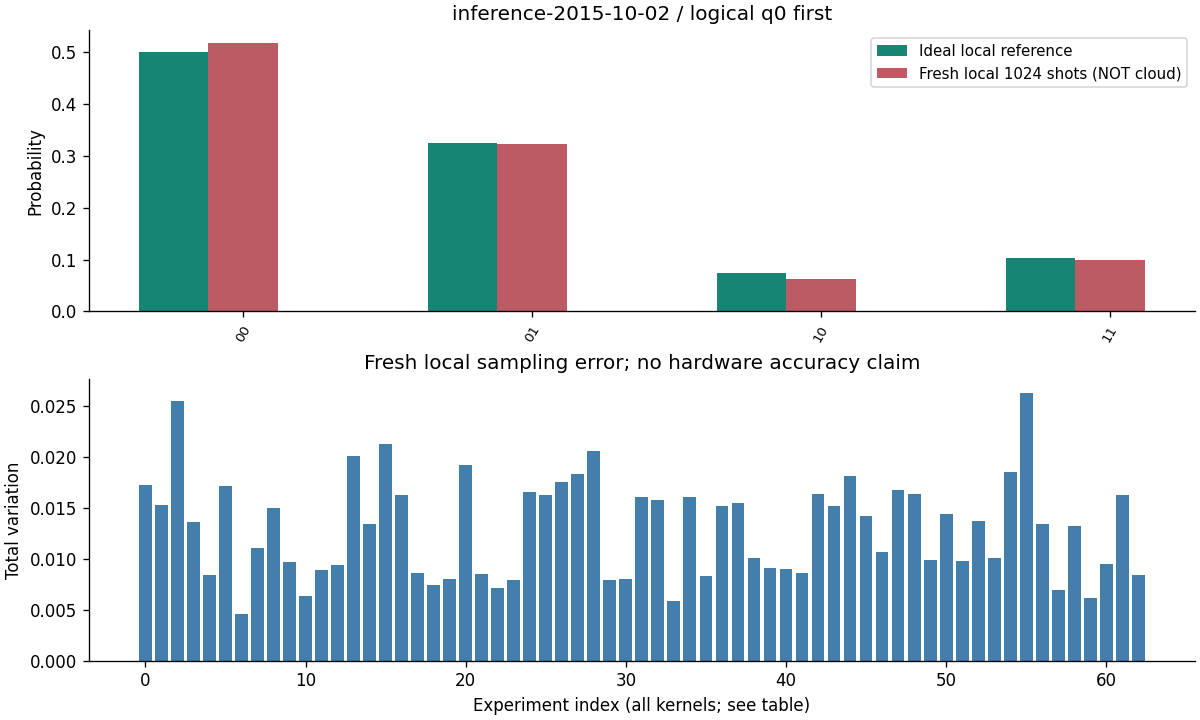

### 官方依据 / Official sources

[安装](https://quafu.com.cn/docs/sdk/install) · [提交与编译](https://quafu.com.cn/docs/sdk/submit) · [结果与位序](https://quafu.com.cn/docs/sdk/results) · [设备约束](https://quafu.com.cn/docs/sdk/devices) · [身份与凭据](https://quafu.com.cn/docs/sdk/login)

旧公开 SDK 参考、本地经典基线、原数据来源及结果误差说明保留在原章节。这次更新不认证 Qiskit/PennyLane 全兼容、行业生产支持、量子优势或安全认证。